In [109]:
from langgraph.graph import StateGraph, START, END
import operator 
from langgraph.types import Send
from pydantic import BaseModel, Field
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage
from typing import TypedDict, List, Annotated, Literal, Optional
from langchain_community.tools import TavilySearchResults
import os 

os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

In [110]:
class Task(BaseModel):
    id: int
    title: str

    goal: str = Field(
        ...,
        description="One sentence describing what the reader should be able to do/understand after this section.",
    )
    bullets: List[str] = Field(
        ...,
        min_length=2,
        max_length=3,
        description="2 concrete, non-overlapping subpoints to cover in this section.",
    )
    target_words: int = Field(
        ...,
        description="Target word count for this section (50-60).",
    )

    tags: List[str] = Field(default_factory=list)
    requires_research: bool = False
    requires_citations: bool = False
    requires_code: bool = False

In [111]:
class Plan(BaseModel):
    blog_title: str
    audience: str = Field(..., description="Who this blog is for.")
    tone: str = Field(..., description="Writing tone (e.g., practical, crisp).")
    blog_kind: Literal["explainer", "tutorial", "news_roundup", "comparison", "system_design"] = "explainer"
    constraints: List[str] = Field(default_factory=list)
    tasks: List[Task]

In [112]:
class EvidenceItem(BaseModel):
    title: str
    url: str
    published_at: Optional[str] = None  # keep if Tavily provides; DO NOT rely on it
    snippet: Optional[str] = None
    source: Optional[str] = None

class RouterDecision(BaseModel):
    needs_research: bool
    mode: Literal["closed_book", "hybrid", "open_book"]
    queries: List[str] = Field(default_factory=list)

class EvidencePack(BaseModel):
    evidence: List[EvidenceItem] = Field(default_factory=list)

In [113]:
class State(TypedDict):
    topic: str 

    # routing / research
    mode: str
    needs_research: bool
    queries: List[str]
    evidence: List[EvidenceItem]
    plan: Optional[Plan]

    # workers
    sections: Annotated[List[str], operator.add]
    final: str

In [114]:
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    max_retries=3
)

In [115]:
# -----------------------------
# Router (decide upfront)
# -----------------------------
ROUTER_SYSTEM = """You are a routing module for a technical blog planner.

Decide whether web research is needed BEFORE planning.

Modes:
- closed_book (needs_research=false):
  Evergreen topics where correctness does not depend on recent facts (concepts, fundamentals).
- hybrid (needs_research=true):
  Mostly evergreen but needs up-to-date examples/tools/models to be useful.
- open_book (needs_research=true):
  Mostly volatile: weekly roundups, "this week", "latest", rankings, pricing, policy/regulation.

If needs_research=true:
- Output 2-3 high-signal queries.
- Queries should be scoped and specific (avoid generic queries like just "AI" or "LLM").
- If user asked for "last week/this week/latest", reflect that constraint IN THE QUERIES.
"""

def router_node(state: State) -> dict:
  topic = state["topic"]
  decider = llm.with_structured_output(RouterDecision)
  decision = decider.invoke(
    [
        SystemMessage(content=ROUTER_SYSTEM),
        HumanMessage(content=f"Topic: {topic}"),
    ]
  )
  return {
    "needs_research": decision.needs_research,
    "mode": decision.mode,
    "queries": decision.queries,
  }

def route_next(state: State) -> str:
  return "research" if state["needs_research"] else "orchestrator"

In [ ]:
# -----------------------------
# Research (Tavily) 
# -----------------------------

def _tavily_search(query: str, max_results: int = 3) -> List[dict]:
    tool = TavilySearchResults(max_results=max_results)
    results = tool.invoke({ "query": query })

    print(results)

    normalized: List[dict] = []
    for r in results or []:
        normalized.append(
            {
                "title": r.get('title') or '',
                "url": r.get("url") or "",
                "snippet": r.get("content") or r.get("snippet") or "",
                "published_at": r.get("published_date") or r.get("published_at"),
                "source": r.get("source"),
            }
        )
    return normalized

# _tavily_search("AI tool usage", 2)


RESEARCH_SYSTEM = """You are a research synthesizer for technical writing.

Given raw web search results, produce a deduplicated list of EvidenceItem objects.

Rules:
- Only include items with a non-empty url.
- Prefer relevant + authoritative sources (company blogs, docs, reputable outlets).
- If a published date is explicitly present in the result payload, keep it as YYYY-MM-DD.
  If missing or unclear, set published_at=null. Do NOT guess.
- Keep snippets short.
- Deduplicate by URL.
- Output MUST be valid JSON matching the EvidencePack schema with an "evidence" key containing a list of items.
"""

def research_node(state: State) -> dict:
    queries = (state.get("queries", []) or [])
    max_results = 3

    raw_results: List[dict] = []

    for q in queries:
        raw_results.extend(_tavily_search(q, max_results=max_results))

    # Deduplicate by URL
    dedup = {}
    for item in raw_results:
        if item.get("url"):
            dedup[item["url"]] = item

    # Pydantic validation 
    evidence = [
        EvidenceItem.model_validate(item)
        for item in dedup.values() 
    ]

    return {"evidence": evidence}

    # if not raw_results:
    #     return {"evidence": []}

    # extractor = llm.with_structured_output(EvidencePack, method="json_mode")
    # pack = extractor.invoke(
    #     [
    #         SystemMessage(content=RESEARCH_SYSTEM),
    #         HumanMessage(content=f"Raw results:\n{raw_results}"),
    #     ]
    # )

    # Deduplicate by URL
    # dedup = {}
    # for e in pack.evidence:
    #     if e.url:
    #         dedup[e.url] = e 

    # return {"evidence": list(dedup.values())}


In [117]:
def fanout(state: State):
    return [
        Send(
            'worker', 
            {
                "task": task.model_dump(),
                'topic': state['topic'],
                "mode": state["mode"],
                "plan": state["plan"].model_dump(),
                "evidence": [e.model_dump() for e in state.get("evidence", [])],
            }
        )  
        for task in state['plan'].tasks
    ]

In [118]:
# -----------------------------
# Orchestrator (Plan)
# -----------------------------
ORCH_SYSTEM = """You are a senior technical writer and developer advocate.
Your job is to produce a highly actionable outline for a technical blog post.

Hard requirements:
- Create 2 sections (tasks) suitable for the topic and audience.
- Each task must include:
  1) id (int)
  2) title (str)
  3) goal (1 sentence description)
  4) bullets (2-3 concrete, specific, non-overlapping strings)
  5) target_words (int, 50-60)

Quality bar:
- Assume the reader is a developer; use correct terminology.
- Bullets must be actionable: build/compare/measure/verify/debug.

Output must be a valid JSON object strictly matching this schema with these exact keys:
{
  "blog_title": "<string>",
  "audience": "<string>",
  "tone": "<string>",
  "blog_kind": "explainer", 
  "constraints": ["<string>"],
  "tasks": [
    {
      "id": 1,
      "title": "<string>",
      "goal": "<string>",
      "bullets": ["<string>", "<string>"],
      "target_words": 50,
      "tags": [],
      "requires_research": false,
      "requires_citations": false,
      "requires_code": false
    }
  ]
}
"""
def orchestrator_node(state: State) -> dict:

  evidence = state.get("evidence", [])
  mode = state.get("mode", "closed_book")
    
  plan = llm.with_structured_output(Plan, method="json_mode").invoke(
    [
      SystemMessage(content=ORCH_SYSTEM),
      HumanMessage(
        content=(
          f"Topic: {state['topic']}\n"
          f"Mode: {mode}\n\n"
          f"Evidence (ONLY use for fresh claims; may be empty):\n"
          f"{[e.model_dump() for e in evidence][:5]}"
        )
      )
    ]
  )
  
  return {'plan': plan}

In [119]:
# -----------------------------
# Worker (write one section)
# -----------------------------
WORKER_SYSTEM = """You are a senior technical writer and developer advocate.
Write ONE section of a technical blog post in Markdown.

Hard constraints:
- Follow the provided Goal and cover ALL Bullets in order (do not skip or merge bullets).
- Stay close to Target words (±15%).
- Output ONLY the section content in Markdown (no blog title H1, no extra commentary).
- Start with a '## <Section Title>' heading.

Scope guard:
- If blog_kind == "news_roundup": do NOT turn this into a tutorial/how-to guide.
  Do NOT teach web scraping, RSS, automation, or "how to fetch news" unless bullets explicitly ask for it.
  Focus on summarizing events and implications.

Grounding policy:
- If mode == open_book:
  - Do NOT introduce any specific event/company/model/funding/policy claim unless it is supported by provided Evidence URLs.
  - For each event claim, attach a source as a Markdown link: ([Source](URL)).
  - Only use URLs provided in Evidence. If not supported, write: "Not found in provided sources."
- If requires_citations == true:
  - For outside-world claims, cite Evidence URLs the same way.
- Evergreen reasoning is OK without citations unless requires_citations is true.

Code:
- If requires_code == true, include at least one minimal, correct code snippet relevant to the bullets.

Style:
- Short paragraphs, bullets where helpful, code fences for code.
- Avoid fluff/marketing. Be precise and implementation-oriented.
"""

def worker_node(payload: dict) -> dict:

    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]

    bullets_text = "\n- " + "\n- ".join(task["bullets"])

    section_md = llm.invoke(
        [
            SystemMessage(content=WORKER_SYSTEM),
            HumanMessage(
                content=(
                    f"Blog: {plan['blog_title']}\n"
                    f"Audience: {plan['audience']}\n"
                    f"Tone: {plan['tone']}\n"
                    f"Topic: {topic}\n\n"
                    f"Section: {task['title']}\n"
                    f"Goal: {task['goal']}\n"
                    f"Target words: {task['target_words']}\n"
                    f"Bullets:{bullets_text}\n"
                )
            ),
        ]
    ).content.strip() 

    return {'sections': [(task['id'], section_md)]}

In [120]:
from pathlib import Path

def reducer_node(state: State) -> dict:
    plan = state['plan']

    ordered_sections = [md for _, md in sorted(state['sections'], key=lambda x: x[0])]
    body = "\n\n".join(ordered_sections).strip()
    final_md = f"## {plan.blog_title}\n\n{body}\n"

    filename = f"{plan.blog_title}.md"
    Path(filename).write_text(final_md, encoding="utf-8")

    return {"final": final_md}

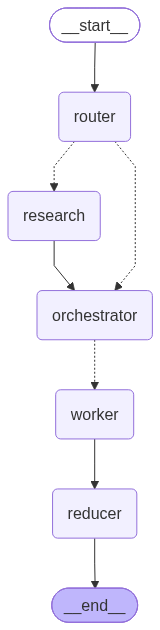

In [121]:
graph = StateGraph(State)
# Register nodes in the graph
graph.add_node('router', router_node)
graph.add_node('research', research_node)
graph.add_node('orchestrator', orchestrator_node)
graph.add_node('worker', worker_node)
graph.add_node('reducer', reducer_node)

graph.add_edge(START, 'router')
# Execute the same worker function N times with different inputs 
graph.add_conditional_edges('router', route_next, {'research': 'research', 'orchestrator': 'orchestrator'})
graph.add_edge('research', 'orchestrator')

graph.add_conditional_edges('orchestrator', fanout, ['worker'])
graph.add_edge('worker', 'reducer')
graph.add_edge('reducer', END)

app = graph.compile() 

app

In [122]:
def run(topic: str):
    out = app.invoke(
        {
            "topic": topic,
            "mode": "",
            "needs_research": False,
            "queries": [],
            "evidence": [],
            "plan": None,
            "sections": [],
            "final": "",
        }
    )

    return out

In [123]:
run("State of Multimodal LLMs in 2026")

[{'title': 'Fastest Open Source Multimodal Models of 2026 - SiliconFlow', 'url': 'https://www.siliconflow.com/articles/fastest-open-source-multimodal-models', 'content': 'Qwen2.5-VL-32B-Instruct is a multimodal large language model released by the Qwen team, part of the Qwen2.5-VL series. This model is not only proficient in recognizing common objects but is highly capable of analyzing texts, charts, icons, graphics, and layouts within images. It acts as a visual agent that can reason and dynamically direct tools, capable of computer and phone use. Additionally, the model can accurately localize objects in images, and generate structured outputs for data like invoices and tables. Compared to its predecessor Qwen2-VL, this version has enhanced mathematical and problem-solving abilities through reinforcement learning, with response styles adjusted to better align with human preferences and a massive 131K context length.\n\n### Pros [...] ## Qwen2.5-VL-32B-Instruct\n\nQwen2.5-VL-32B-Instr

OutputParserException: Failed to parse EvidencePack from completion {"evidence": [{"url": "https://www.siliconflow.com/articles/fastest-open-source-multimodal-models", "snippet": "Qwen2.5-VL-32B-Instruct is a multimodal large language model released by the Qwen team, part of the Qwen2.5-VL series. This model is not only proficient in recognizing common objects but is highly capable of analyzing texts, charts, icons, graphics, and layouts within images.", "published_at": null}, {"url": "https://github.com/xjywhu/Awesome-Multimodal-LLM-for-Code", "snippet": "76. WebWorld: The Browser as a World Model for Self-Improving Web Code ... 2026.08.31 (EMNLP 2026 Main).", "published_at": null}, {"url": "https://yourgpt.ai/blog/general/best-llms", "snippet": "MiniMax M3 is an open-weight model released on June 1, 2026 by Shanghai-based MiniMax. It combines frontier-level coding performance, a 1 million token context window, and native multimodal capabilities across text, images, and video within a